# 3. Recommandation de quartiers


Il y a un score d'importance de 0 a 3 pour chaqye variable. L'algo renvoie l'iris qui lui correspond le mieux. c'est la moyenne des rangs pour ses variables. Enusite on fait un K NN, afin de cherche les iris plus proche du quartier idéal. Le budget filtre les resultats. 

# Bibliotheque

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
SAVE_DIR = "../save/"
N_RECO = 10
K_TYPES = 6

COLUMNS_DENSITE = ['nb_commerces_alimentaires', 'nb_commerces_detail', 'nb_services_personnels', 'nb_restaurants_bars',
                   'nb_sante', 'nb_lieux_municipaux', 'nb_places_stationnement', 'places_payant_mixte',
                   'nb_lm_marches_alimentaires', 'nb_lm_bibliotheques', 'nb_lm_gymnases', 'nb_lm_terrains_de_sports']

# 1 = plus la valeur est grande, mieux c'est ; -1 = plus elle est petite, mieux c'est
CRITERES = {
    "transports": {'dist_metro_m': -1, 'dist_train_m': -1, 'dist_tram_m': -1, 'dist_bus_m': -1, 'dist_velib_m': -1,
                   'nb_passages_tc_jour': 1, 'nb_lignes_tc': 1},
    "accessibilite_pmr": {'part_quais_accessibles_pmr_%': 1},
    "ecoles": {'dist_creche_m': -1, 'dist_ecole_m': -1, 'dist_college_m': -1, 'dist_lycee_m': -1, 'ips_ecole_proche': 1,
               'ips_lycee_proche': 1, 'college_taux_reussite': 1, 'college_va_reussite': 1},
    "verdure": {'part_surface_verte': 1, 'dist_espace_vert_visitable_m': -1, 'densite_arbres_km2': 1, 'hauteur_mediane_arbres_m': 1,
                'part_arbres_adultes_matures': 1},
    "calme": {'indice_bruit_moy': -1, 'indice_air_moy': -1, 'part_point_noir_air_bruit_%': -1},
    "commerces": {'dist_supermarche_m': -1, 'dist_superette_m': -1, 'dist_boulangerie_m': -1, 'dist_boucherie_poissonnerie_m': -1,
                  'dist_primeur_m': -1, 'dist_pressing_laverie_m': -1, 'densite_lm_marches_alimentaires': 1,
                  'densite_commerces_alimentaires': 1, 'densite_commerces_detail': 1, 'densite_services_personnels': 1},
    "sante": {'dist_pharmacie_m': -1, 'dist_medecin_m': -1, 'dist_dentiste_m': -1, 'densite_sante': 1},
    "sorties": {'densite_restaurants_bars': 1},
    "services_publics": {'densite_lieux_municipaux': 1, 'dist_bureau_poste_m': -1},
    "sport_culture": {'dist_salle_sport_m': -1, 'dist_cinema_m': -1, 'dist_librairie_m': -1, 'densite_lm_bibliotheques': 1,
                      'densite_lm_gymnases': 1, 'densite_lm_terrains_de_sports': 1},
    "voiture": {'part_menages_parking_%': 1, 'densite_places_stationnement': 1, 'densite_places_payant_mixte': 1},
    "grands_logements": {'part_5_pieces_plus_%': 1, 'part_100m2_plus_%': 1, 'part_suroccupation_%': -1},
    "quartier_jeune": {'part_15_24_ans_%': 1, 'part_etudiants_%': 1},
}

PROFILS = {
    "Famille": {"poids": {"ecoles": 3, "verdure": 3, "calme": 2, "grands_logements": 2, "commerces": 1, "sante": 1}, "prix_m2_max": 11000, "loyer_m2_max": None,
                "distances_max": {"creche": 300, "supermarche": 500}},
    "Jeune actif": {"poids": {"transports": 3, "sorties": 3, "sport_culture": 2, "commerces": 1}, "prix_m2_max": None, "loyer_m2_max": 27,
                    "distances_max": {"salle_sport": 500}},
    "Étudiant": {"poids": {"transports": 3, "quartier_jeune": 2, "sorties": 2, "sport_culture": 1, "services_publics": 1}, "prix_m2_max": None, "loyer_m2_max": 24,
                 "distances_max": {"superette": 300}},
    "Retraité": {"poids": {"calme": 3, "sante": 3, "commerces": 2, "verdure": 2}, "prix_m2_max": 12000, "loyer_m2_max": None,
                 "distances_max": {"pharmacie": 300, "medecin": 300, "boulangerie": 300}},
    "Automobiliste": {"poids": {"voiture": 3, "calme": 1, "commerces": 1}, "prix_m2_max": 10000, "loyer_m2_max": None,
                      "distances_max": {"supermarche": 800}},
}

COLUMNS_INFO = ['nom_iris', 'nom_quartier', 'nom_com', 'prix_m2_median', 'loyer_ref_m2']

## Chargement

Les comptages (commerces, santé…) sont ramenés au km² pour ne pas favoriser les grands IRIS. On ne recommande que les IRIS d'habitat (`typ_iris == "H"`) : les IRIS d'activité et les bois n'ont presque pas de logements.

In [3]:
iris = gpd.read_parquet(SAVE_DIR + "iris_features.parquet").set_index("code_iris")
for col in COLUMNS_DENSITE:
    iris["densite_" + col.removeprefix("nb_")] = iris[col] / iris["surface_iris_km2"]

habitat = iris[iris["typ_iris"] == "H"].copy()
print(iris.shape, habitat.shape)

(992, 195) (861, 195)


# Score par critère

In [4]:
scores = pd.DataFrame(index=habitat.index)
for critere, colonnes in CRITERES.items():
    rangs = [(habitat[col] * signe).rank(pct=True) for col, signe in colonnes.items()]
    scores[critere] = pd.concat(rangs, axis=1).mean(axis=1)

scores = scores.fillna(scores.median())
display(scores.describe().round(2))

,transports,accessibilite_pmr,ecoles,verdure,calme,commerces,sante,sorties,services_publics,sport_culture,voiture,grands_logements,quartier_jeune
count,861.00,861.00,861.00,861.00,861.00,861.00,861.00,861.00,861.00,861.00,861.00,861.00,861.00
mean,0.50,0.50,0.50,0.50,0.50,0.50,0.50,0.50,0.50,0.50,0.50,0.50,0.50
std,0.13,0.26,0.13,0.17,0.22,0.19,0.22,0.29,0.21,0.10,0.18,0.24,0.28
min,0.14,0.04,0.10,0.05,0.10,0.05,0.00,0.00,0.04,0.23,0.03,0.01,0.01
25%,0.40,0.24,0.41,0.39,0.33,0.37,0.34,0.25,0.34,0.43,0.37,0.30,0.26
50%,0.50,0.50,0.50,0.50,0.51,0.51,0.50,0.50,0.50,0.50,0.51,0.50,0.50
75%,0.60,0.77,0.59,0.62,0.66,0.64,0.68,0.75,0.66,0.57,0.64,0.70,0.74
max,0.85,0.77,0.84,0.94,0.98,0.90,0.98,1.00,1.00,0.84,0.94,1.00,1.00


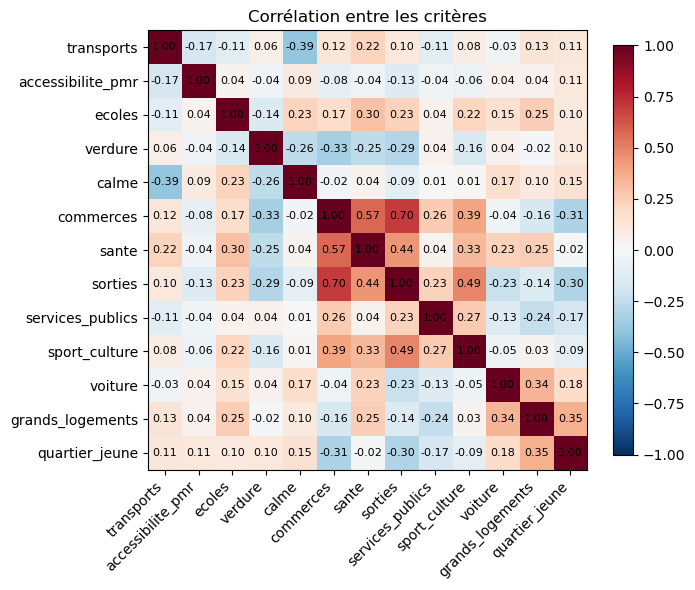

In [5]:
corr = scores.corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
ax.set_title("Corrélation entre les critères")
fig.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout()
plt.show()

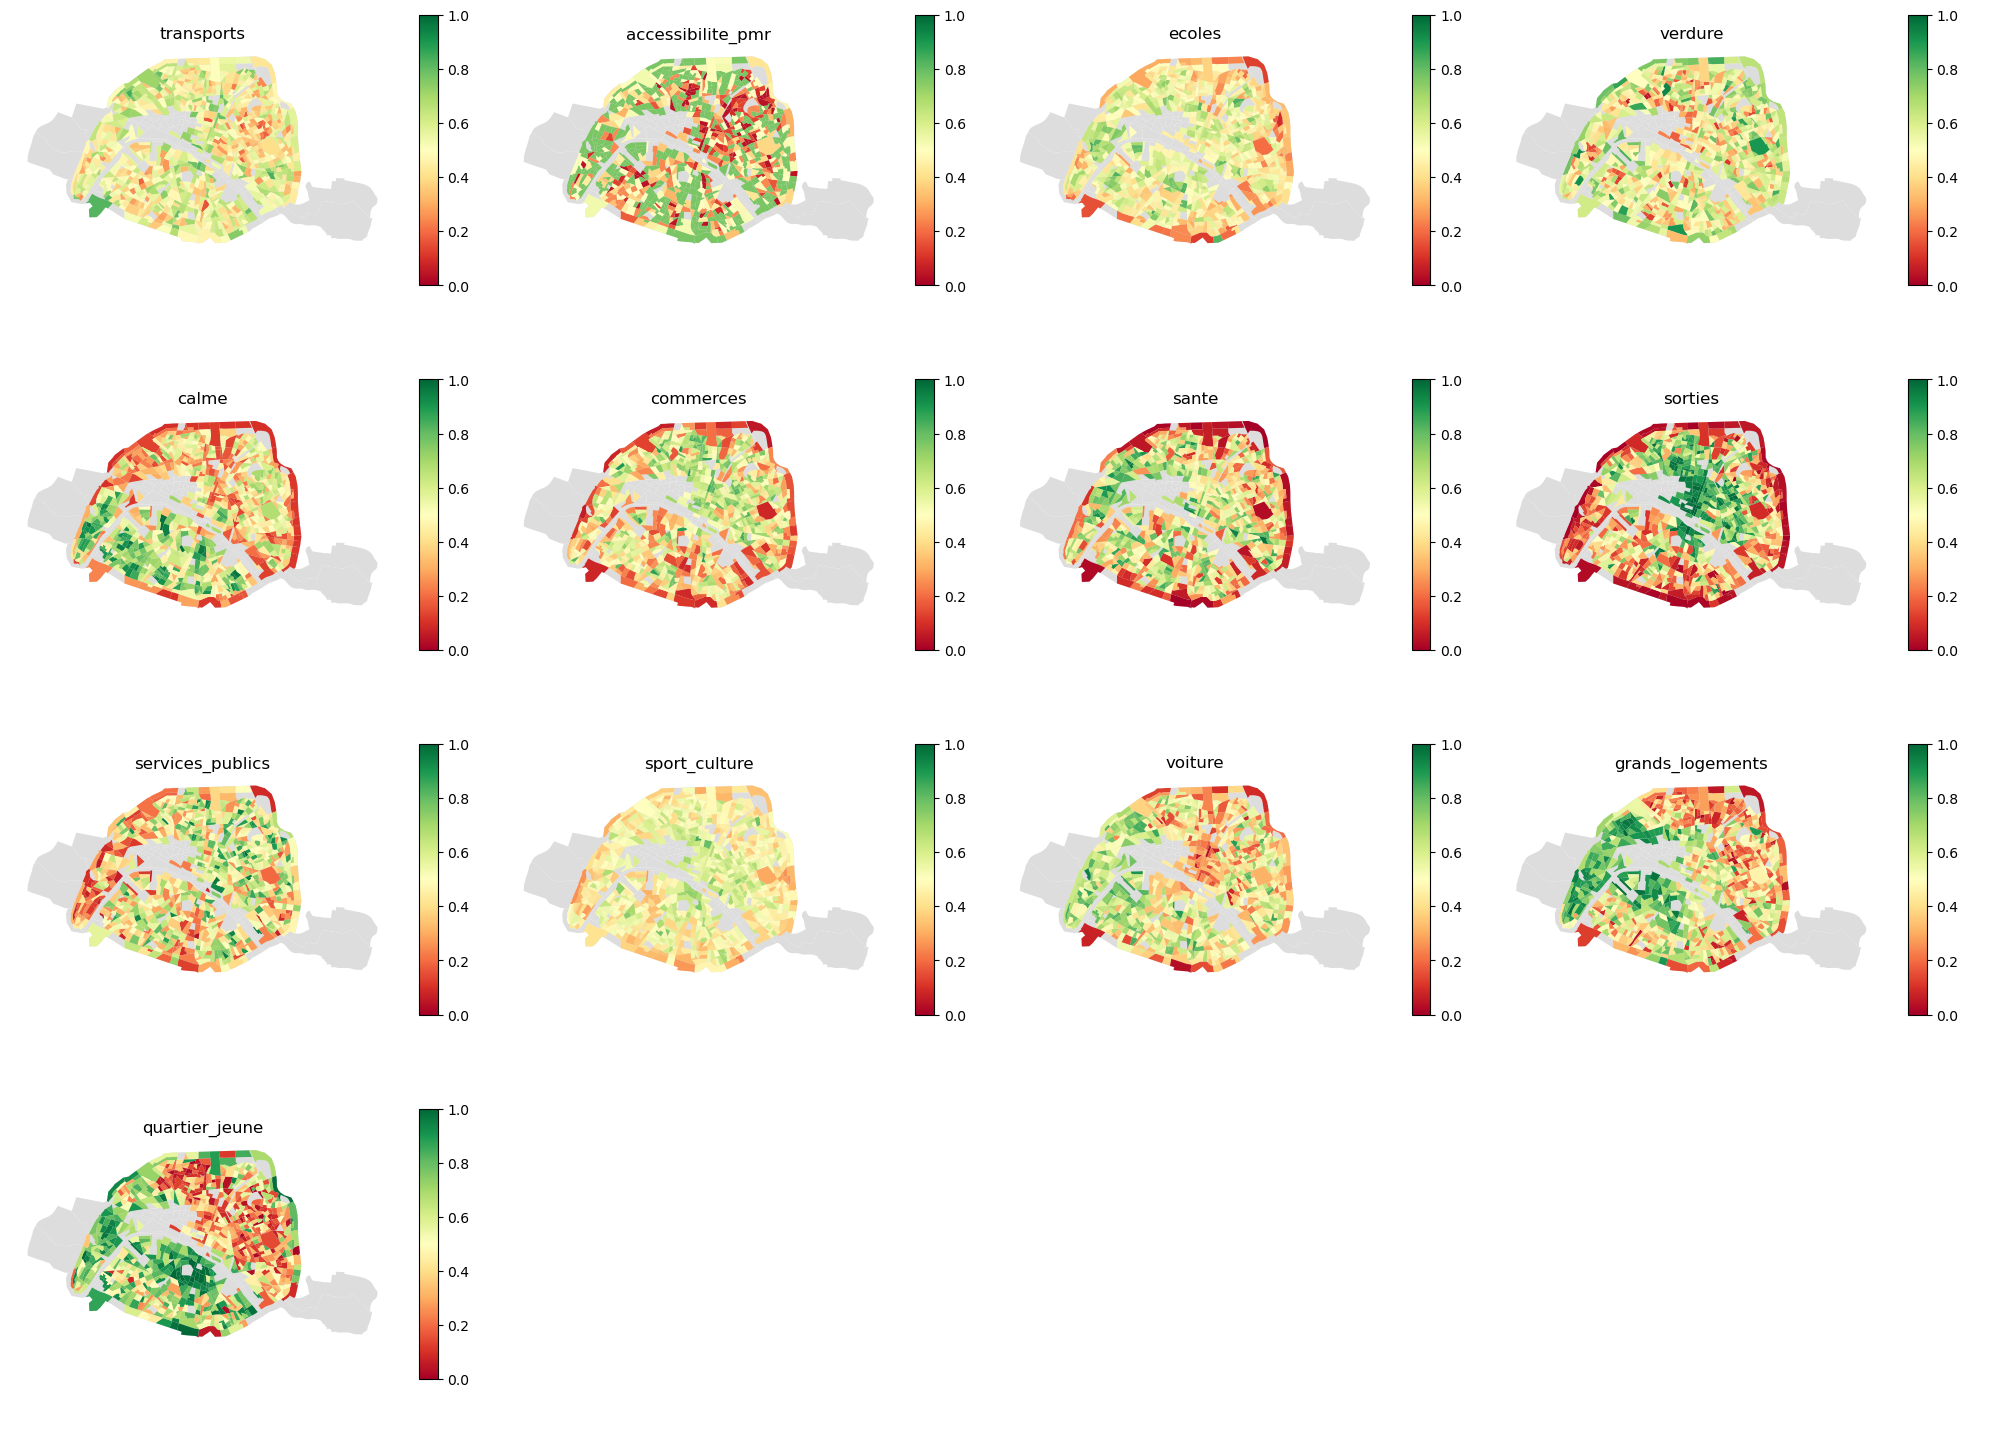

In [6]:
carte = habitat[["geometry"]].join(scores)
fig, axes = plt.subplots(4, 4, figsize=(20, 15))
for ax in axes.flat:
    ax.set_axis_off()
for ax, critere in zip(axes.flat, scores.columns):
    iris.plot(ax=ax, color="#dddddd")
    carte.plot(column=critere, ax=ax, cmap="RdYlGn", vmin=0, vmax=1, legend=True)
    ax.set_title(critere)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

## Types de quartiers (k-means)

On veut voir si il y a des quartiers qui différe assez pour créer des frontieres ou si c'est uniquement des variations légere. Il y a que tres peu de changement entre les quartiers

In [7]:
for k in range(3, 10):
    labels = KMeans(k, n_init=20, random_state=0).fit_predict(scores)
    print(k, round(silhouette_score(scores, labels), 3))

3 0.153
4 0.127
5 0.121
6 0.118
7 0.119
8 0.12
9 0.118


In [8]:
types = KMeans(K_TYPES, n_init=20, random_state=0).fit_predict(scores)
profil_types = scores.groupby(types).mean() - scores.mean()
noms_types = profil_types.apply(lambda ligne: f"{ligne.name} : " + " + ".join(ligne.nlargest(2).index), axis=1)  # numéro : deux types peuvent avoir le même nom
scores["type_quartier"] = noms_types.loc[types].values

display(profil_types.round(2).set_index(noms_types).style.background_gradient(cmap="RdYlGn", axis=None))
display(scores["type_quartier"].value_counts())

,transports,accessibilite_pmr,ecoles,verdure,calme,commerces,sante,sorties,services_publics,sport_culture,voiture,grands_logements,quartier_jeune
0 : sorties + commerces,0.060000,-0.300000,-0.000000,-0.010000,-0.110000,0.140000,0.070000,0.260000,0.080000,0.050000,-0.070000,-0.070000,-0.210000
1 : quartier_jeune + sante,0.060000,0.010000,0.070000,-0.040000,-0.010000,0.050000,0.190000,0.110000,-0.060000,0.030000,0.080000,0.180000,0.230000
2 : calme + services_publics,-0.050000,-0.010000,-0.020000,0.040000,0.090000,-0.050000,-0.090000,-0.150000,0.070000,-0.020000,0.030000,-0.120000,-0.050000
3 : grands_logements + quartier_jeune,-0.040000,0.110000,0.030000,0.020000,0.180000,-0.150000,-0.050000,-0.290000,-0.150000,-0.050000,0.110000,0.250000,0.250000
4 : verdure + quartier_jeune,0.020000,0.060000,-0.140000,0.130000,-0.230000,-0.250000,-0.320000,-0.380000,-0.080000,-0.100000,-0.120000,-0.120000,0.090000
5 : sorties + accessibilite_pmr,-0.050000,0.200000,0.020000,-0.090000,-0.000000,0.150000,0.060000,0.270000,0.070000,0.040000,-0.080000,-0.130000,-0.240000


type_quartier
2 : calme + services_publics             180
1 : quartier_jeune + sante               163
0 : sorties + commerces                  157
5 : sorties + accessibilite_pmr          143
3 : grands_logements + quartier_jeune    128
4 : verdure + quartier_jeune              90
Name: count, dtype: int64

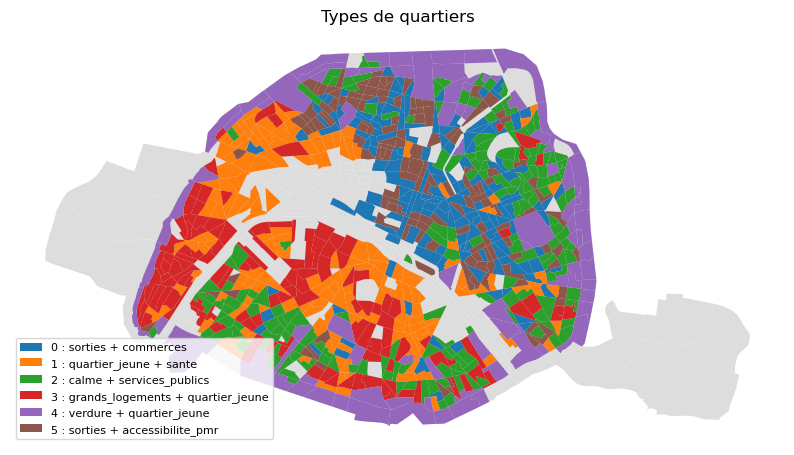

In [9]:
fig, ax = plt.subplots(figsize=(10, 7))
iris.plot(ax=ax, color="#dddddd")
habitat[["geometry"]].join(scores).plot(column="type_quartier", ax=ax, categorical=True, cmap="tab10", legend=True,
                                        legend_kwds={"loc": "lower left", "fontsize": 8})
ax.set_title("Types de quartiers")
ax.set_axis_off()
plt.show()

## Recommandation k-NN

L'idée est que pour chaque crieteres, le quartier idéal doit avoir 1 partout. Pour les criteres plus important tel que si on met 3, alors il vaut 3 fois plus qu'un quartier qui vaut 1 
Ainsi on peut connaitre la liste des Iris qui correspondent le plus au criteres de la personne.

In [10]:
CRITERES_SCORES = list(CRITERES)
RECOS = {}
for nom, profil in PROFILS.items():
    poids = pd.Series(profil["poids"]).reindex(CRITERES_SCORES, fill_value=0)

    candidats = scores[CRITERES_SCORES]
    if profil["prix_m2_max"]:
        candidats = candidats[habitat.loc[candidats.index, "prix_m2_median"] <= profil["prix_m2_max"]]

    if profil["loyer_m2_max"]:
        candidats = candidats[habitat.loc[candidats.index, "loyer_ref_m2"] <= profil["loyer_m2_max"]]

    for lieu, distance_max in profil["distances_max"].items():
        candidats = candidats[habitat.loc[candidats.index, f"dist_{lieu}_m"] <= distance_max]

    knn = NearestNeighbors(n_neighbors=N_RECO).fit(candidats * poids)
    distances, positions = knn.kneighbors(poids.to_frame().T)

    reco = habitat.loc[candidats.index[positions[0]], COLUMNS_INFO].join(scores[list(profil["poids"]) + ["type_quartier"]])
    reco["distance"] = distances[0]
    RECOS[nom] = reco
    
    print(f"{nom} : {len(candidats)} IRIS dans le budget")
    display(reco.round(2))

Famille : 661 IRIS dans le budget


,nom_iris,nom_quartier,nom_com,prix_m2_median,loyer_ref_m2,ecoles,verdure,calme,grands_logements,commerces,sante,type_quartier,distance
code_iris,,,,,,,,,,,,,
751145610,Plaisance 10,Plaisance,Paris 14e Arrondissement,8833.0,24.74,0.58,0.68,0.82,0.71,0.60,0.85,1 : quartier_jeune + sante,1.78
751135203,Croulebarbe 3,Croulebarbe,Paris 13e Arrondissement,10322.0,26.00,0.60,0.81,0.78,0.70,0.21,0.38,3 : grands_logements + quartier_jeune,1.81
751155903,Grenelle 3,Grenelle,Paris 15e Arrondissement,10250.0,25.97,0.65,0.68,0.91,0.49,0.57,0.72,2 : calme + services_publics,1.82
751156019,Javel 19,Javel 15Art,Paris 15e Arrondissement,9776.0,25.97,0.74,0.57,0.95,0.60,0.56,0.46,2 : calme + services_publics,1.84
751155916,Grenelle 16,Grenelle,Paris 15e Arrondissement,11000.0,25.97,0.50,0.72,0.92,0.79,0.44,0.57,3 : grands_logements + quartier_jeune,1.91
751124614,Picpus 14,Picpus,Paris 12e Arrondissement,9151.0,24.14,0.73,0.67,0.59,0.55,0.38,0.57,2 : calme + services_publics,1.92
751197607,Combat 7,Combat,Paris 19e Arrondissement,8430.0,22.72,0.56,0.84,0.63,0.73,0.21,0.38,2 : calme + services_publics,1.95
751197616,Combat 16,Combat,Paris 19e Arrondissement,8772.0,22.72,0.60,0.67,0.66,0.84,0.41,0.33,3 : grands_logements + quartier_jeune,1.95
751083201,Europe 1,Europe,Paris 8e Arrondissement,10000.0,28.14,0.69,0.69,0.35,0.89,0.45,0.76,1 : quartier_jeune + sante,1.96


Jeune actif : 629 IRIS dans le budget


,nom_iris,nom_quartier,nom_com,prix_m2_median,loyer_ref_m2,transports,sorties,sport_culture,commerces,type_quartier,distance
code_iris,,,,,,,,,,,
751093502,Faubourg Montmartre 2,Faubourg-Montmartre,Paris 9e Arrondissement,10526.0,26.00,0.77,0.97,0.66,0.72,0 : sorties + commerces,1.02
751103906,Porte Saint-Martin 6,Porte-Saint-Martin,Paris 10e Arrondissement,9621.0,24.19,0.75,0.88,0.68,0.81,0 : sorties + commerces,1.08
751051803,Jardin des Plantes 3,Jardin-des-Plantes,Paris 5e Arrondissement,11250.0,25.22,0.73,0.85,0.70,0.87,1 : quartier_jeune + sante,1.09
751176805,Épinettes 5,Epinettes,Paris 17e Arrondissement,9211.0,24.19,0.79,0.98,0.56,0.82,0 : sorties + commerces,1.09
751010202,Les Halles 2,Halles,Paris 1er Arrondissement,11644.0,26.00,0.81,0.99,0.53,0.68,0 : sorties + commerces,1.15
751124808,Quinze-Vingts 8,Quinze-Vingts,Paris 12e Arrondissement,9781.0,24.19,0.74,0.92,0.61,0.71,1 : quartier_jeune + sante,1.16
751093609,Rochechouart 9,Rochechouart,Paris 9e Arrondissement,11072.0,26.00,0.73,0.85,0.65,0.65,0 : sorties + commerces,1.22
751114106,Folie Méricourt 6,Folie-Méricourt,Paris 11e Arrondissement,10556.0,24.19,0.65,0.97,0.66,0.77,0 : sorties + commerces,1.27
751103703,Saint-Vincent de Paul 3,Saint-Vincent-de-Paul,Paris 10e Arrondissement,9354.0,26.00,0.75,0.94,0.51,0.79,0 : sorties + commerces,1.27


Étudiant : 180 IRIS dans le budget


,nom_iris,nom_quartier,nom_com,prix_m2_median,loyer_ref_m2,transports,quartier_jeune,sorties,sport_culture,services_publics,type_quartier,distance
code_iris,,,,,,,,,,,,
751187202,Chapelle 2,La Chapelle,Paris 18e Arrondissement,6957.0,21.12,0.70,0.69,0.80,0.47,0.56,0 : sorties + commerces,1.35
751124701,Bercy 1,Bercy,Paris 12e Arrondissement,9058.0,22.72,0.69,0.90,0.54,0.63,0.96,1 : quartier_jeune + sante,1.38
751197522,Amérique 22,Amérique,Paris 19e Arrondissement,7632.0,21.12,0.61,0.52,0.88,0.78,0.76,0 : sorties + commerces,1.57
751197405,Pont de Flandre 5,Pont-de-Flandre,Paris 19e Arrondissement,7617.0,21.12,0.74,0.57,0.54,0.45,0.28,0 : sorties + commerces,1.74
751208013,Charonne 13,Charonne,Paris 20e Arrondissement,8100.0,21.12,0.54,0.87,0.55,0.38,0.56,2 : calme + services_publics,1.83
751197312,Villette 12,Villette,Paris 19e Arrondissement,8444.0,21.12,0.57,0.63,0.72,0.60,0.15,5 : sorties + accessibilite_pmr,1.84
751135014,Gare 14,Gare,Paris 13e Arrondissement,8378.0,21.12,0.60,0.95,0.45,0.51,0.29,3 : grands_logements + quartier_jeune,1.85
751197307,Villette 7,Villette,Paris 19e Arrondissement,7629.0,21.12,0.48,0.70,0.69,0.48,0.86,0 : sorties + commerces,1.86
751197402,Pont de Flandre 2,Pont-de-Flandre,Paris 19e Arrondissement,8388.0,21.12,0.60,0.53,0.53,0.44,0.62,2 : calme + services_publics,1.92


Retraité : 716 IRIS dans le budget


,nom_iris,nom_quartier,nom_com,prix_m2_median,loyer_ref_m2,calme,sante,commerces,verdure,type_quartier,distance
code_iris,,,,,,,,,,,
751145610,Plaisance 10,Plaisance,Paris 14e Arrondissement,8833.0,24.74,0.82,0.85,0.60,0.68,1 : quartier_jeune + sante,1.24
751155903,Grenelle 3,Grenelle,Paris 15e Arrondissement,10250.0,25.97,0.91,0.72,0.57,0.68,2 : calme + services_publics,1.37
751155709,Saint-Lambert 9,Saint-Lambert,Paris 15e Arrondissement,8847.0,25.02,0.72,0.91,0.80,0.50,1 : quartier_jeune + sante,1.40
751155915,Grenelle 15,Grenelle,Paris 15e Arrondissement,10169.0,25.97,0.67,0.86,0.73,0.56,1 : quartier_jeune + sante,1.49
751208011,Charonne 11,Charonne,Paris 20e Arrondissement,8383.0,21.12,0.69,0.68,0.76,0.69,2 : calme + services_publics,1.55
751155714,Saint-Lambert 14,Saint-Lambert,Paris 15e Arrondissement,9325.0,25.02,0.80,0.85,0.62,0.43,1 : quartier_jeune + sante,1.57
751176713,Batignolles 13,Batignolles,Paris 17e Arrondissement,10564.0,25.22,0.67,0.80,0.88,0.48,0 : sorties + commerces,1.58
751020802,Bonne Nouvelle 2,Bonne-Nouvelle,Paris 2e Arrondissement,10676.0,27.54,0.74,0.86,0.78,0.38,5 : sorties + accessibilite_pmr,1.59
751156005,Javel 5,Javel 15Art,Paris 15e Arrondissement,9196.0,25.97,0.87,0.71,0.56,0.55,3 : grands_logements + quartier_jeune,1.59


Automobiliste : 521 IRIS dans le budget


,nom_iris,nom_quartier,nom_com,prix_m2_median,loyer_ref_m2,voiture,calme,commerces,type_quartier,distance
code_iris,,,,,,,,,,
751155728,Saint-Lambert 28,Saint-Lambert,Paris 15e Arrondissement,9728.0,25.02,0.83,0.81,0.63,1 : quartier_jeune + sante,0.66
751156020,Javel 20,Javel 15Art,Paris 15e Arrondissement,9417.0,25.97,0.82,0.65,0.60,1 : quartier_jeune + sante,0.76
751145509,Petit Montrouge 9,Petit-Montrouge,Paris 14e Arrondissement,9186.0,25.22,0.78,0.71,0.78,1 : quartier_jeune + sante,0.76
751135122,Maison Blanche 22,Maison-Blanche,Paris 13e Arrondissement,8917.0,24.74,0.80,0.68,0.64,1 : quartier_jeune + sante,0.76
751135120,Maison Blanche 20,Maison-Blanche,Paris 13e Arrondissement,9114.0,24.74,0.87,0.62,0.41,2 : calme + services_publics,0.80
751156018,Javel 18,Javel 15Art,Paris 15e Arrondissement,9725.0,25.97,0.79,0.71,0.57,2 : calme + services_publics,0.81
751145615,Plaisance 15,Plaisance,Paris 14e Arrondissement,9335.0,24.74,0.74,0.92,0.77,5 : sorties + accessibilite_pmr,0.82
751145508,Petit Montrouge 8,Petit-Montrouge,Paris 14e Arrondissement,9056.0,25.22,0.80,0.87,0.46,3 : grands_logements + quartier_jeune,0.82
751155722,Saint-Lambert 22,Saint-Lambert,Paris 15e Arrondissement,8838.0,25.02,0.80,0.71,0.50,2 : calme + services_publics,0.82


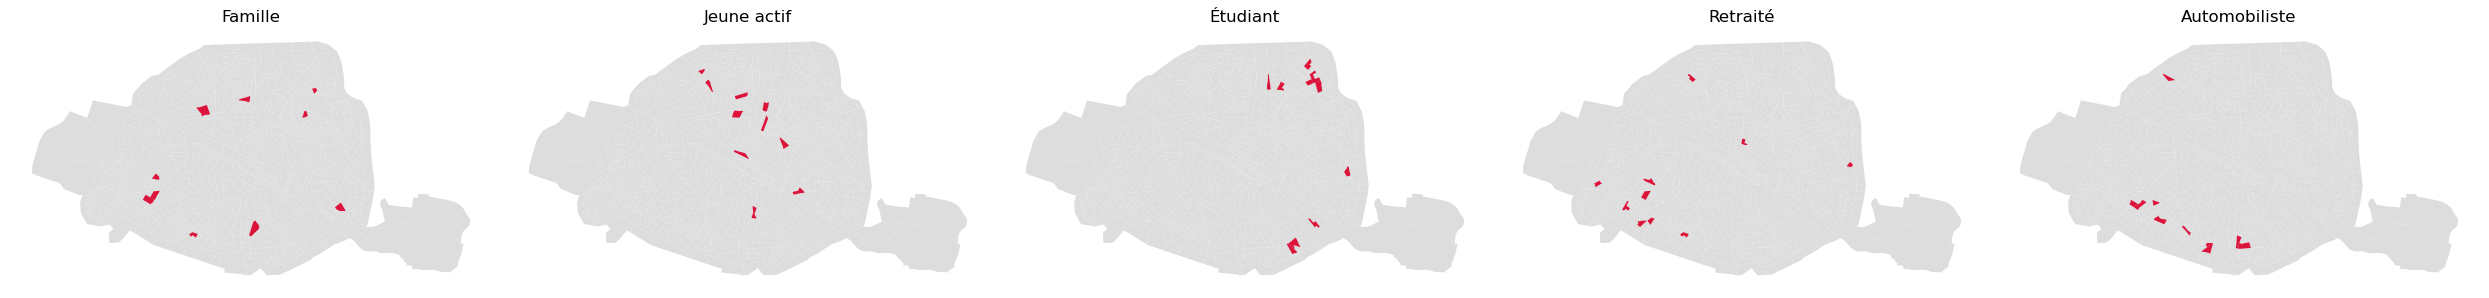

In [11]:
fig, axes = plt.subplots(1, len(RECOS), figsize=(5 * len(RECOS), 4.5))
for ax, (nom, reco) in zip(axes, RECOS.items()):
    iris.plot(ax=ax, color="#dddddd")
    habitat.loc[reco.index].plot(ax=ax, color="crimson")
    ax.set_title(nom)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

## Vérification

Malheureusement, nous n'avons pas trouvé de quartiers avec des notations. ainsi la vérifications reste que partiel. 
On a essayer alors de regarder la différence entre les iris recommandés en fonction des criteres et de voir si les meilleurs résultats sont au dessus de la moyenne.

In [12]:
verif = pd.DataFrame({nom: scores.loc[reco.index, list(PROFILS[nom]["poids"])].mean() for nom, reco in RECOS.items()}).T
display(verif.round(2).style.background_gradient(cmap="RdYlGn", vmin=0, vmax=1, axis=None))

communs = pd.DataFrame({a: {b: len(RECOS[a].index.intersection(RECOS[b].index)) for b in RECOS} for a in RECOS})
display(communs)

,calme,commerces,ecoles,grands_logements,quartier_jeune,sante,services_publics,sorties,sport_culture,transports,verdure,voiture
Famille,0.730000,0.460000,0.630000,0.700000,nan,0.560000,nan,nan,nan,nan,0.690000,nan
Jeune actif,nan,0.760000,nan,nan,nan,nan,nan,0.930000,0.620000,0.740000,nan,nan
Étudiant,nan,nan,nan,nan,0.700000,nan,0.530000,0.630000,0.510000,0.610000,nan,nan
Retraité,0.760000,0.700000,nan,nan,nan,0.800000,nan,nan,nan,nan,0.540000,nan
Automobiliste,0.730000,0.580000,nan,nan,nan,nan,nan,nan,nan,nan,nan,0.810000


,Famille,Jeune actif,Étudiant,Retraité,Automobiliste
Famille,10,0,0,2,0
Jeune actif,0,10,0,0,0
Étudiant,0,0,10,0,0
Retraité,2,0,0,10,0
Automobiliste,0,0,0,0,10


## Sauvegarde

Maintenant, nous avons notre fichier avec lequel les utilisateurs peuvent intéragir.

`../save/iris_scores.parquet`

In [13]:
scores.to_parquet(SAVE_DIR + "iris_scores.parquet")